# 03 펌프 센서 간 상관관계 히트맵

1. 원본 센서 데이터 불러오기
2. 피어슨 상관계수와 센서 쌍별 관측 행 수 계산
3. 히트맵을 확인하고 PNG로 저장

`data/sensor.csv`에서 원본 52개 센서를 모두 읽습니다. Python 커널에 `pandas`, `numpy`, `matplotlib`가 필요합니다.

## 1. 원본 센서 파일 불러오기

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# 저장소 최상위나 notebooks/에서 실행할 수 있도록 공통 데이터 경로를 찾습니다.
cwd = Path.cwd()
project_root = next(
    (path for path in (cwd, *cwd.parents) if (path / "src/pump_missingness_audit.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("kkobugi 저장소나 notebooks 폴더에서 커널을 실행하세요.")

sys.path.insert(0, str(project_root))
from src.pump_missingness_audit import default_source, read_sensor_data

source = default_source()
raw = read_sensor_data(source)
sensor_columns = sorted(column for column in raw.columns if column.startswith("sensor_"))
print(f"입력: {source.relative_to(project_root).as_posix()} · {len(raw):,}행 · 센서 {len(sensor_columns)}개")

입력: data/sensor.csv · 220,320행 · 센서 52개


## 2. 센서 쌍별 상관계수 계산

피어슨 상관계수는 두 센서에 값이 모두 있는 같은 시각의 행으로 계산합니다. 결측을 채우지 않기 때문에 센서 쌍마다 사용한 행 수가 다를 수 있습니다. `sensor_15`처럼 관측값이 없거나 비교할 값에 변동이 없으면 계수는 비어 있습니다. 아래 표는 절댓값이 큰 상관계수 10쌍과 계산에 사용한 행 수를 보여줍니다.

In [ ]:
readings = raw[sensor_columns]
correlation = readings.corr(method="pearson", min_periods=2)

# 두 센서가 모두 관측된 행의 수를 센서 쌍별로 셉니다.
observed = readings.notna().to_numpy(dtype="float64")
overlap = (observed.T @ observed).astype("int64")
pair_count = pd.DataFrame(overlap, index=sensor_columns, columns=sensor_columns)

# 대각선과 대칭으로 중복되는 쌍을 한 번씩만 표시합니다.
row, col = np.triu_indices(len(sensor_columns), k=1)
pairs = pd.DataFrame({
    "센서 A": correlation.index[row],
    "센서 B": correlation.columns[col],
    "피어슨 r": correlation.to_numpy()[row, col],
    "동시 관측 행 수": overlap[row, col],
}).dropna(subset=["피어슨 r"])
strongest = pairs.loc[pairs["피어슨 r"].abs().nlargest(10).index]
display(strongest.reset_index(drop=True).round({"피어슨 r": 4}))
undefined_sensors = correlation.index[correlation.isna().all(axis=1)]
print("상관계수를 계산할 수 없는 센서:", ", ".join(undefined_sensors) or "없음")

,센서 A,센서 B,피어슨 r,동시 관측 행 수
0,sensor_19,sensor_20,0.9982,220304
1,sensor_20,sensor_21,0.9971,220304
2,sensor_19,sensor_21,0.9960,220304
3,sensor_14,sensor_16,0.9904,220289
4,sensor_19,sensor_22,0.9882,220279
5,sensor_22,sensor_23,0.9869,220279
6,sensor_20,sensor_22,0.9865,220279
7,sensor_19,sensor_24,0.9856,220304
8,sensor_21,sensor_24,0.9849,220304
9,sensor_19,sensor_25,0.9848,220284


상관계수를 계산할 수 없는 센서: sensor_15


## 3. 히트맵 확인 및 PNG 저장

파란색은 음의 상관, 붉은색은 양의 상관, 회색은 계산할 수 없는 셀입니다. 상관계수는 같은 시각의 선형 관계를 나타냅니다. 저장 경로는 `figures/sensor_correlations/pearson_correlation.png`입니다.

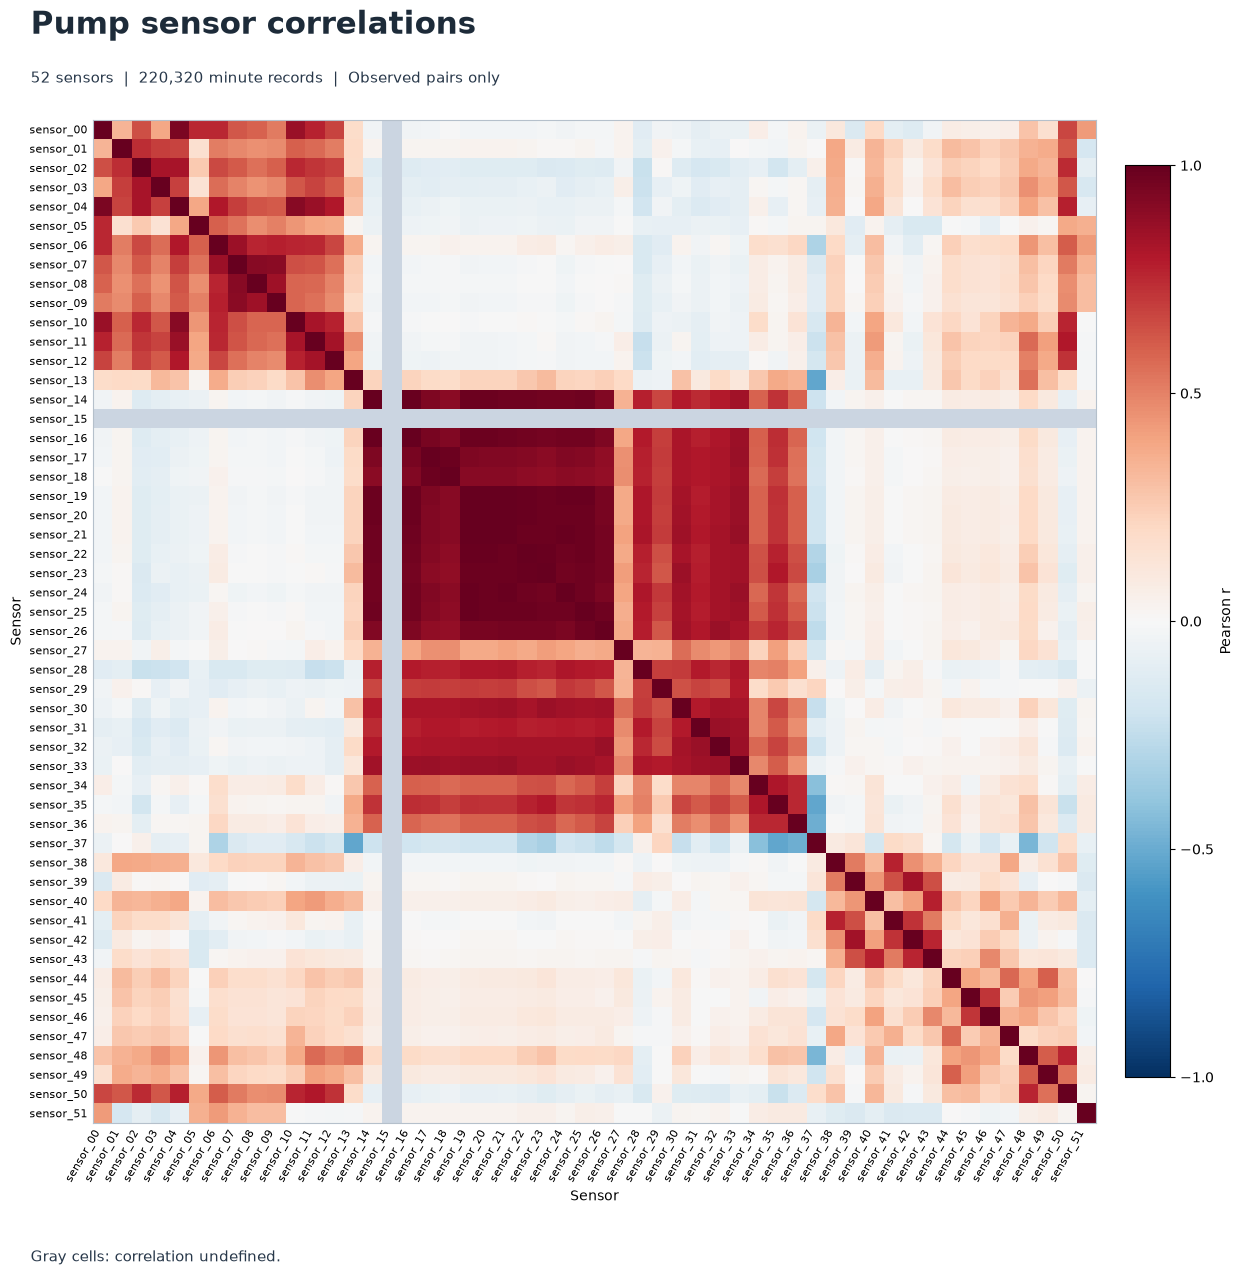

저장: figures/sensor_correlations/pearson_correlation.png


In [ ]:
output_dir = project_root / "figures/sensor_correlations"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "pearson_correlation.png"

cmap = plt.get_cmap("RdBu_r").with_extremes(bad="#cbd5e1")
fig, ax = plt.subplots(figsize=(14.8, 13.2))
fig.subplots_adjust(left=.12, right=.89, bottom=.13, top=.89)
image = ax.imshow(correlation.to_numpy(), cmap=cmap, vmin=-1, vmax=1, interpolation="nearest")
positions = np.arange(len(sensor_columns))
ax.set_xticks(positions, sensor_columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(positions, sensor_columns, fontsize=8)
ax.tick_params(length=0, pad=4)
ax.set_xlabel("Sensor")
ax.set_ylabel("Sensor")
for spine in ax.spines.values():
    spine.set_color("#b5c0cb")
bar = fig.colorbar(image, ax=ax, fraction=.04, pad=.025, ticks=[-1, -.5, 0, .5, 1])
bar.set_label("Pearson r")
fig.text(.12, .955, "Pump sensor correlations", fontsize=22, fontweight="bold", color="#1d2b39")
fig.text(
    .12, .918,
    f"{len(sensor_columns)} sensors  |  {len(raw):,} minute records  |  Observed pairs only",
    fontsize=11, color="#28384a",
)
fig.text(.12, .025, "Gray cells: correlation undefined.", fontsize=11, color="#28384a")
fig.savefig(output_path, dpi=150, facecolor="white")
plt.show()
print(f"저장: {output_path.relative_to(project_root).as_posix()}")